# Tarea: Máquinas de Vectores de Soporte (SVM), Árboles de Decisión y Random Forest
**Dataset seleccionado:** Red Wine Quality (`WineQT.csv`)

---

## 1. Kernel cuadrático

Considere el kernel polinomial de grado 2 dado por:
$$K(x, z) = (x^T z + 1)^2$$

### 1.1 Mapeo explícito $\phi(x)$ para $d = 2$
Sea $x = [x_1, x_2]^T \in \mathbb{R}^2$ y $z = [z_1, z_2]^T \in \mathbb{R}^2$. Desarrollamos el producto:
$$K(x, z) = (x_1 z_1 + x_2 z_2 + 1)^2$$
$$K(x, z) = x_1^2 z_1^2 + x_2^2 z_2^2 + 1 + 2 x_1 x_2 z_1 z_2 + 2 x_1 z_1 + 2 x_2 z_2$$

Reescribiendo como un producto interno $\phi(x)^T \phi(z)$, obtenemos el mapeo explícito $\phi: \mathbb{R}^2 \to \mathbb{R}^6$:
$$\phi(x) = \begin{bmatrix} 1 \\ \sqrt{2}x_1 \\ \sqrt{2}x_2 \\ x_1^2 \\ \sqrt{2}x_1 x_2 \\ x_2^2 \end{bmatrix}$$

Evaluando para $x = [2, -3]^T$:
$$\phi([2, -3]^T) = \begin{bmatrix} 1 \\ 2\sqrt{2} \\ -3\sqrt{2} \\ 4 \\ -6\sqrt{2} \\ 9 \end{bmatrix}$$

In [1]:
import numpy as np

def phi(v):
    v1, v2 = v[0], v[1]
    return np.array([
        1.0,
        np.sqrt(2) * v1,
        np.sqrt(2) * v2,
        v1**2,
        np.sqrt(2) * v1 * v2,
        v2**2
    ])

def kernel_cuadratico(x, z):
    return (np.dot(x, z) + 1)**2

x = np.array([2.0, -3.0])
z = np.array([1.0, 1.0])

phi_x = phi(x)
phi_z = phi(z)

prod_interno = np.dot(phi_x, phi_z)
k_val = kernel_cuadratico(x, z)

print("phi([2, -3]^T) =", np.round(phi_x, 4))
print(f"Producto interno phi(x)^T phi(z) = {prod_interno:.4f}")
print(f"Kernel K(x, z)                   = {k_val:.4f}")
assert np.isclose(prod_interno, k_val), "Los valores deben coincidir"
print("Verificación exitosa: phi(x)^T phi(z) == K(x, z)")

phi([2, -3]^T) = [ 1.      2.8284 -4.2426  4.     -8.4853  9.    ]
Producto interno phi(x)^T phi(z) = -0.0000
Kernel K(x, z)                   = 0.0000
Verificación exitosa: phi(x)^T phi(z) == K(x, z)


### 1.2 Dimensión de $\phi(x)$ en $\mathbb{R}^d$ y ventaja computacional del truco del kernel

* **Dimensión del espacio transformado:** Para un vector $x \in \mathbb{R}^d$, el mapeo $\phi(x)$ contiene:
  * $1$ término constante (grado 0).
  * $d$ términos lineales $x_i$ (grado 1).
  * $d$ términos cuadráticos puros $x_i^2$ (grado 2).
  * $\binom{d}{2} = \frac{d(d-1)}{2}$ términos cruzados $x_i x_j$ con $i < j$ (grado 2).
  
  Sumando todos los componentes, la dimensión del espacio de características es:
  $$\text{dim}(\phi(x)) = 1 + d + d + \frac{d(d-1)}{2} = \frac{d^2 + 3d + 2}{2} = \binom{d + 2}{2}$$

* **¿Por qué calcular $K(x, z)$ directamente es mucho más barato que calcular $\phi(x)^T \phi(z)$?**
  1. **Complejidad temporal:** Calcular $K(x, z) = (x^T z + 1)^2$ requiere un único producto punto en el espacio original $\mathbb{R}^d$ más una suma y un cuadrado, lo cual toma $\mathcal{O}(d)$ operaciones. En cambio, construir $\phi(x)$ explícitamente y realizar el producto interno en $\mathbb{R}^{\binom{d+2}{2}}$ toma $\mathcal{O}(d^2)$ operaciones.
  2. **Complejidad espacial (memoria):** Al usar el kernel directamente nunca se almacenan los vectores expandidos de tamaño $\mathcal{O}(d^2)$ por cada ejemplo de entrenamiento. Cuando $d$ es grande (por ejemplo, $d = 10,000$ píxeles o palabras), $\binom{d+2}{2} \approx 5 \times 10^7$ dimensiones por muestra, haciendo inviable el mapeo explícito mientras que el truco del kernel sigue operando en $\mathcal{O}(d)$.

---
## 2. Clasificación con SVC y Kernel Gaussiano (RBF)

### 2.1 Exploración y preparación del dataset
Utilizamos el dataset **Red Wine Quality (`WineQT.csv`)**, el cual cuenta con **1,143 muestras** (cumpliendo el rango de 1,000 a 10,000 ejemplos), **6 variables predictoras cuantitativas** y **3 clases categóricas** de calidad de vino:
* **Clase 0 (Baja):** puntajes 3, 4 y 5.
* **Clase 1 (Media):** puntaje 6.
* **Clase 2 (Alta):** puntajes 7 y 8.

**Descripción física/química de las 6 variables seleccionadas:**
1. `alcohol`: Porcentaje de alcohol por volumen (% vol).
2. `volatile acidity`: Cantidad de ácido acético en el vino (g/dm³); niveles muy altos producen sabor desagradable a vinagre.
3. `sulphates`: Aditivo de sulfato de potasio (g/dm³) que actúa como antimicrobiano y antioxidante.
4. `citric acid`: Cantidad de ácido cítrico (g/dm³), aporta frescura y sabor.
5. `total sulfur dioxide`: Cantidad total de dióxido de azufre $SO_2$ libre y ligado (mg/dm³).
6. `density`: Densidad del vino (g/cm³), estrechamente ligada al porcentaje de alcohol y contenido de azúcar.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Cargar dataset
df = pd.read_csv('WineQT.csv')

# Seleccionar 6 features cuantitativas
features = [
    'alcohol',
    'volatile acidity',
    'sulphates',
    'citric acid',
    'total sulfur dioxide',
    'density'
]

# Crear variable objetivo categórica de 3 clases
def map_quality(q):
    if q <= 5:
        return 0  # Baja
    elif q == 6:
        return 1  # Media
    else:
        return 2  # Alta

df['target'] = df['quality'].apply(map_quality)
class_names = ['Baja (0)', 'Media (1)', 'Alta (2)']

X = df[features].copy()
y = df['target'].copy()

print(f"Número total de ejemplos: {X.shape[0]}")
print(f"Número de features: {X.shape[1]}")
print(f"Valores nulos por columna:\n{X.isnull().sum()}\n")

print("Distribución de clases:")
conteo = y.value_counts().sort_index()
proporcion = y.value_counts(normalize=True).sort_index() * 100
resumen_clases = pd.DataFrame({'Cantidad': conteo, 'Proporción (%)': proporcion.round(2)})
resumen_clases.index = class_names
display(resumen_clases)

display(X.describe().round(3))

# División estratificada 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Tamaño X_train: {X_train.shape}, Tamaño X_test: {X_test.shape}")

Número total de ejemplos: 1143
Número de features: 6
Valores nulos por columna:
alcohol                 0
volatile acidity        0
sulphates               0
citric acid             0
total sulfur dioxide    0
density                 0
dtype: int64

Distribución de clases:


,Cantidad,Proporción (%)
Baja (0),522,45.67
Media (1),462,40.42
Alta (2),159,13.91


,alcohol,volatile acidity,sulphates,citric acid,total sulfur dioxide,density
count,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000
mean,10.442,0.531,0.658,0.268,45.915,0.997
std,1.082,0.180,0.170,0.197,32.782,0.002
min,8.400,0.120,0.330,0.000,6.000,0.990
25%,9.500,0.392,0.550,0.090,21.000,0.996
50%,10.200,0.520,0.620,0.250,37.000,0.997
75%,11.100,0.640,0.730,0.420,61.000,0.998
max,14.900,1.580,2.000,1.000,289.000,1.004


Tamaño X_train: (914, 6), Tamaño X_test: (229, 6)


### 2.2 Fronteras de decisión de SVC con kernel RBF en 2 variables
Seleccionamos las dos variables con mayor correlación respecto a la calidad (`alcohol` y `volatile acidity`) para visualizar las fronteras de decisión en 2D. Dividimos `X_train` en un subconjunto de entrenamiento y validación interna (80/20) para reportar el desempeño de entrenamiento y validación en cada configuración.

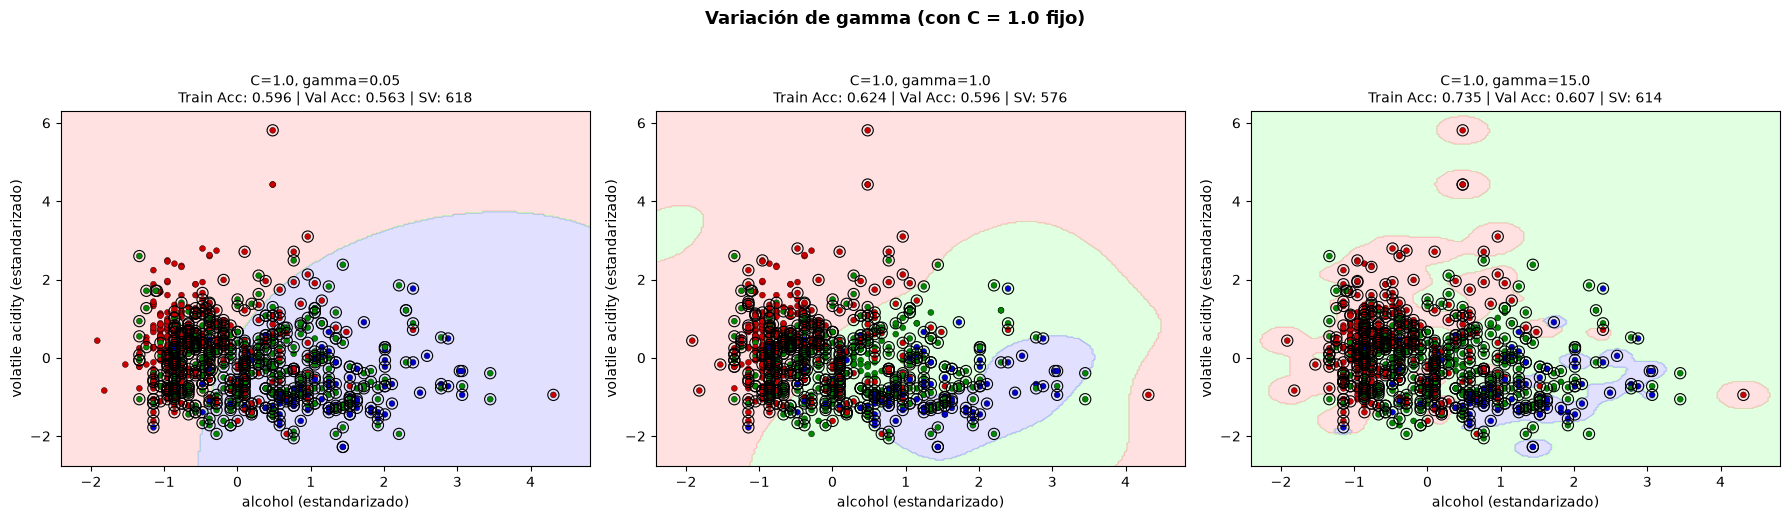

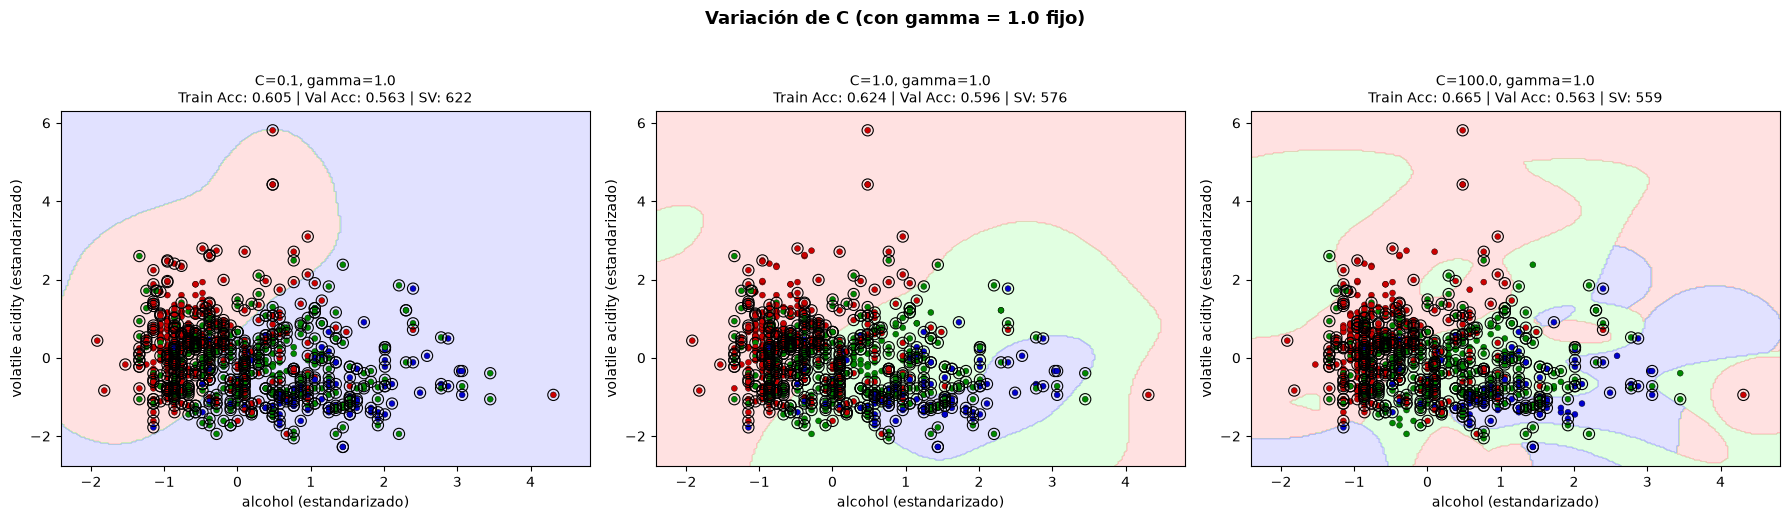

,C,gamma,Train Acc,Val Acc,Vectores Soporte
0,1.0,0.05,0.5964,0.5628,618
1,1.0,1.00,0.6238,0.5956,576
2,1.0,15.00,0.7346,0.6066,614
3,0.1,1.00,0.6047,0.5628,622
4,1.0,1.00,0.6238,0.5956,576
5,100.0,1.00,0.6648,0.5628,559


In [3]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from matplotlib.colors import ListedColormap

# Subconjunto 2D y división train / val interna
feat_2d = ['alcohol', 'volatile acidity']
X_tr_2d, X_val_2d, y_tr_2d, y_val_2d = train_test_split(
    X_train[feat_2d], y_train, test_size=0.20, random_state=42, stratify=y_train
)

scaler_2d = StandardScaler()
X_tr_2d_sc = scaler_2d.fit_transform(X_tr_2d)
X_val_2d_sc = scaler_2d.transform(X_val_2d)

# Configuraciones: 3 valores de gamma con C fijo, y 3 valores de C con gamma fijo
configs_gamma = [(1.0, 0.05), (1.0, 1.0), (1.0, 15.0)]
configs_C = [(0.1, 1.0), (1.0, 1.0), (100.0, 1.0)]

def plot_svc_grid(configs, title_prefix):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    cmap_bg = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_pts = ListedColormap(['#CC0000', '#008800', '#0000CC'])
    
    x_min, x_max = X_tr_2d_sc[:, 0].min() - 0.5, X_tr_2d_sc[:, 0].max() + 0.5
    y_min, y_max = X_tr_2d_sc[:, 1].min() - 0.5, X_tr_2d_sc[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    
    resultados = []
    for ax, (C_val, gamma_val) in zip(axes, configs):
        clf = SVC(kernel='rbf', C=C_val, gamma=gamma_val, random_state=42)
        clf.fit(X_tr_2d_sc, y_tr_2d)
        
        acc_tr = accuracy_score(y_tr_2d, clf.predict(X_tr_2d_sc))
        acc_val = accuracy_score(y_val_2d, clf.predict(X_val_2d_sc))
        n_sv = len(clf.support_)
        
        resultados.append({
            'C': C_val, 'gamma': gamma_val,
            'Train Acc': round(acc_tr, 4), 'Val Acc': round(acc_val, 4),
            'Vectores Soporte': n_sv
        })
        
        Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.contourf(xx, yy, Z, alpha=0.35, cmap=cmap_bg)
        ax.scatter(X_tr_2d_sc[:, 0], X_tr_2d_sc[:, 1], c=y_tr_2d, cmap=cmap_pts, s=18, edgecolors='k', linewidth=0.3)
        ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
                   s=65, facecolors='none', edgecolors='black', linewidths=0.8, label='Vectores soporte')
        ax.set_title(f"C={C_val}, gamma={gamma_val}\nTrain Acc: {acc_tr:.3f} | Val Acc: {acc_val:.3f} | SV: {n_sv}", fontsize=10)
        ax.set_xlabel('alcohol (estandarizado)')
        ax.set_ylabel('volatile acidity (estandarizado)')
    
    fig.suptitle(title_prefix, fontsize=13, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(resultados)

df_res_gamma = plot_svc_grid(configs_gamma, "Variación de gamma (con C = 1.0 fijo)")
df_res_C = plot_svc_grid(configs_C, "Variación de C (con gamma = 1.0 fijo)")
display(pd.concat([df_res_gamma, df_res_C], ignore_index=True))

#### Análisis de las fronteras de decisión:
* **Efecto de `gamma` (con $C = 1.0$ fijo):** El parámetro $\gamma$ controla el radio de influencia de cada vector de soporte ($K(x, z) = \exp(-\gamma \|x - z\|^2)$):
  * Con $\gamma = 0.05$ (pequeño), el radio de influencia es muy amplio, produciendo fronteras casi lineales y suaves. El modelo tiene alto sesgo (*underfitting*), aunque generaliza de manera estable.
  * Con $\gamma = 1.0$ (moderado), la frontera se curva suavemente para adaptarse a la estructura no lineal de los datos, logrando un buen equilibrio entre entrenamiento y validación.
  * Con $\gamma = 15.0$ (grande), cada punto tiene influencia muy local, creando "islas" cerradas alrededor de puntos individuales. La exactitud de entrenamiento sube notablemente mientras cae la de validación (claro **sobreajuste / overfitting**) y aumenta el número de vectores de soporte necesarios.
* **Efecto de `C` (con $\gamma = 1.0$ fijo):** El parámetro $C$ penaliza los errores de clasificación (violaciones del margen):
  * Con $C = 0.1$ (pequeño), se prioriza un margen ancho tolerando más puntos mal clasificados dentro del margen; las fronteras son simples.
  * Con $C = 1.0$, se equilibra amplitud del margen y error empírico.
  * Con $C = 100.0$ (grande), el modelo penaliza fuertemente cualquier error en entrenamiento, deformando la frontera para clasificar correctamente puntos ruidosos o atípicos en zonas solapadas, lo que reduce el margen e incrementa la varianza (*overfitting*).

### 2.3 Búsqueda de hiperparámetros con `Pipeline` y `GridSearchCV` (6 variables)
Construimos un `Pipeline` que integra `StandardScaler` y `SVC(kernel='rbf')` para evitar fuga de datos (*data leakage*) durante la validación cruzada de 5 pliegues (`StratifiedKFold`). Exploramos $C$ y $\gamma$ en escala logarítmica.

Mejores hiperparámetros SVC: {'svc__C': np.float64(10.0), 'svc__gamma': np.float64(0.1)}
Mejor accuracy CV (5-fold): 0.6455


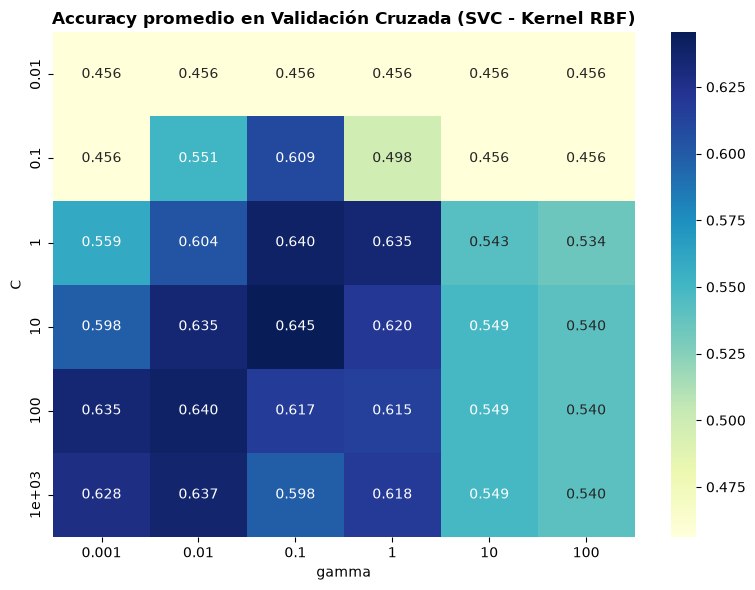

Accuracy final de SVC en X_test: 0.6681


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipe_svc = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', random_state=42))
])

C_range = np.logspace(-2, 3, 6)       # [0.01, 0.1, 1, 10, 100, 1000]
gamma_range = np.logspace(-3, 2, 6)   # [0.001, 0.01, 0.1, 1, 10, 100]

param_grid_svc = {
    'svc__C': C_range,
    'svc__gamma': gamma_range
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_svc = GridSearchCV(
    pipe_svc,
    param_grid=param_grid_svc,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)
grid_svc.fit(X_train, y_train)

print(f"Mejores hiperparámetros SVC: {grid_svc.best_params_}")
print(f"Mejor accuracy CV (5-fold): {grid_svc.best_score_:.4f}")

# Mapa de calor (Heatmap) de los resultados de validación cruzada
scores_matrix = grid_svc.cv_results_['mean_test_score'].reshape(len(C_range), len(gamma_range))

plt.figure(figsize=(8, 6))
sns.heatmap(
    scores_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    xticklabels=[f"{g:.3g}" for g in gamma_range],
    yticklabels=[f"{c:.3g}" for c in C_range]
)
plt.title("Accuracy promedio en Validación Cruzada (SVC - Kernel RBF)", fontsize=12, fontweight='bold')
plt.xlabel("gamma")
plt.ylabel("C")
plt.tight_layout()
plt.show()

# Evaluación única sobre el conjunto de prueba X_test
best_svc = grid_svc.best_estimator_
test_acc_svc = accuracy_score(y_test, best_svc.predict(X_test))
print(f"Accuracy final de SVC en X_test: {test_acc_svc:.4f}")

---
## 3. Árboles de Decisión y Random Forest

### 3.1 Árbol de Decisión: búsqueda de `max_depth` y visualización de profundidad 3
Utilizamos exactamente los mismos conjuntos `X_train` y `y_train` (y la misma partición de validación cruzada `cv_strategy`) para buscar la profundidad máxima óptima (`max_depth`). Posteriormente, ajustamos un árbol de profundidad 3 para interpretar sus reglas de decisión.

Mejor max_depth Árbol de Decisión: {'max_depth': None}
Mejor accuracy CV Árbol: 0.6083


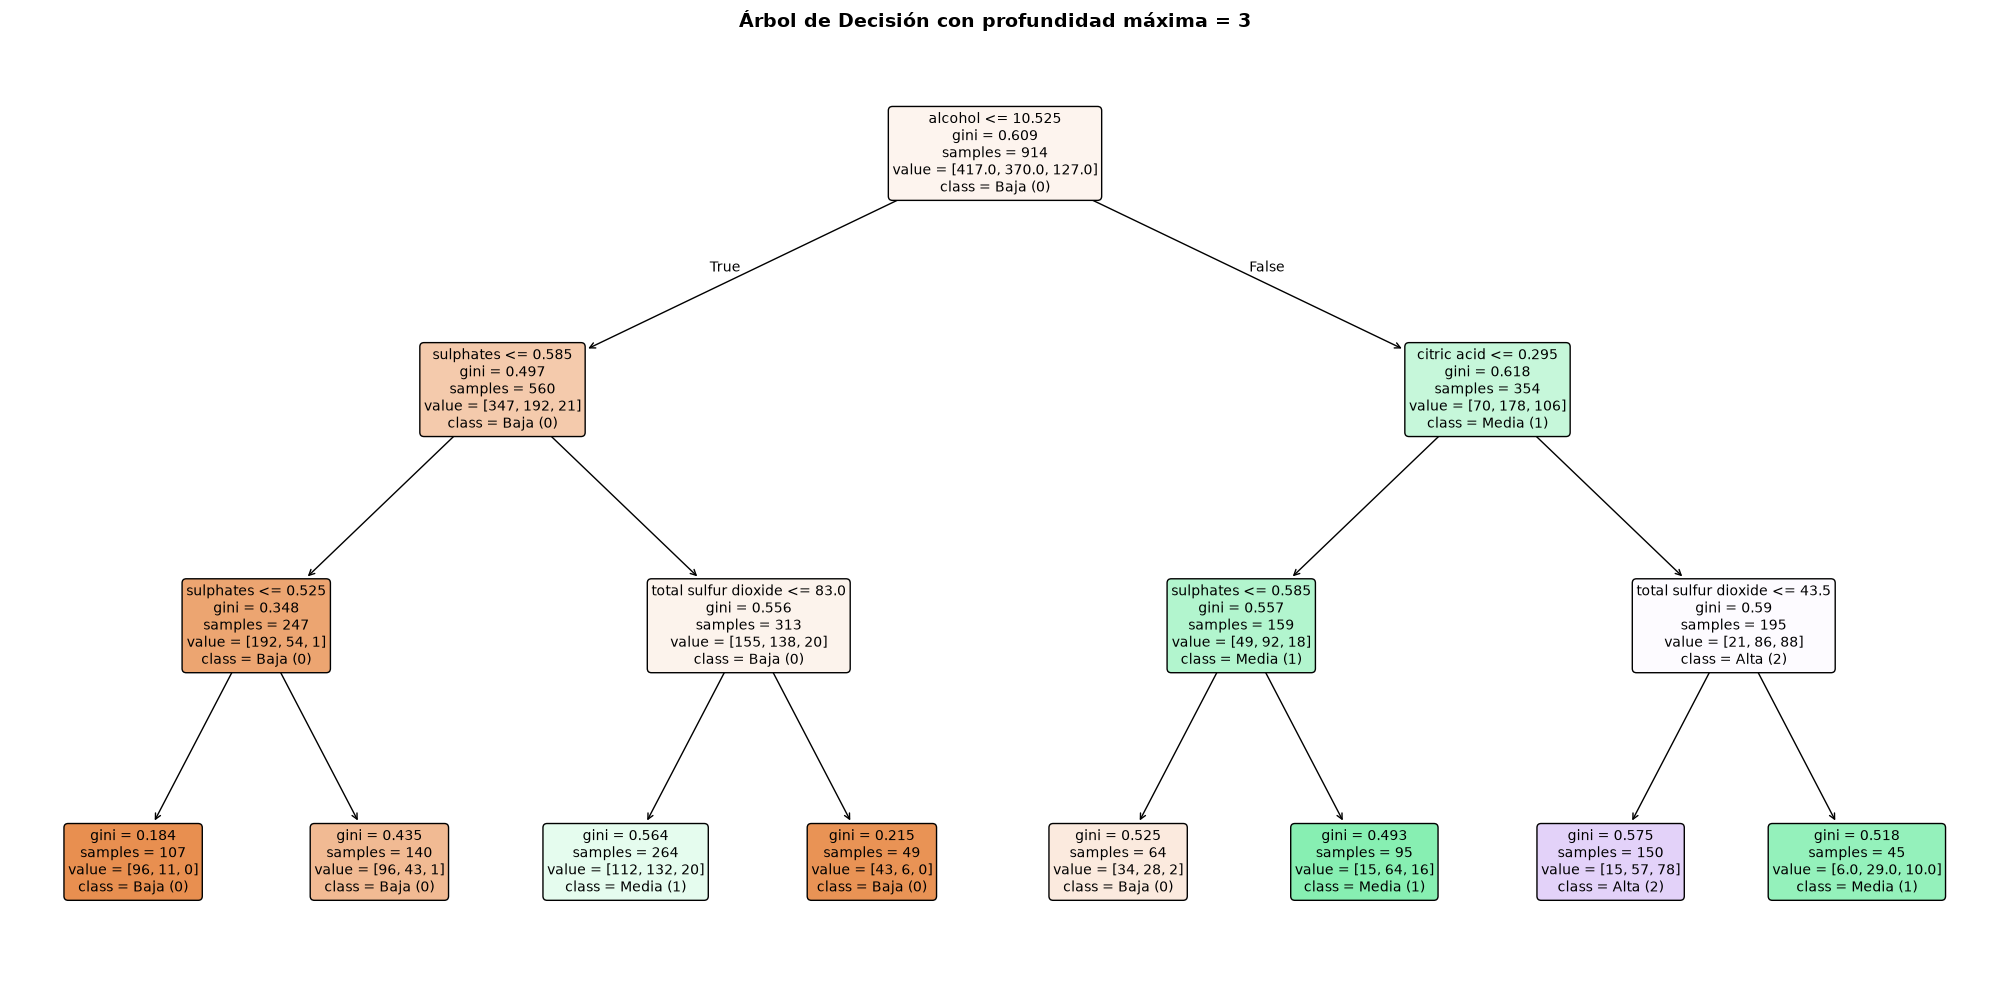

Accuracy final del mejor Árbol de Decisión en X_test: 0.6376


In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

param_grid_dt = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, 12, None]
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)
grid_dt.fit(X_train, y_train)

print(f"Mejor max_depth Árbol de Decisión: {grid_dt.best_params_}")
print(f"Mejor accuracy CV Árbol: {grid_dt.best_score_:.4f}")

# Árbol de profundidad 3 para inspección visual
dt_depth3 = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_depth3.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(
    dt_depth3,
    feature_names=features,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión con profundidad máxima = 3", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Evaluación única sobre X_test del mejor árbol
best_dt = grid_dt.best_estimator_
test_acc_dt = accuracy_score(y_test, best_dt.predict(X_test))
print(f"Accuracy final del mejor Árbol de Decisión en X_test: {test_acc_dt:.4f}")

#### Interpretación de las reglas del árbol de profundidad 3:
1. **Nodo raíz (`alcohol`):** La primera división separa los vinos según su porcentaje de alcohol (alrededor de $\le 10.525\%$). Los vinos con menor graduación alcohólica tienden mayoritariamente hacia la **Clase 0 (Baja)**, mientras que aquellos con mayor alcohol se desplazan hacia calidad **Media (1)** y **Alta (2)**.
2. **Segundo nivel (`volatile acidity` y `sulphates`):**
   * En la rama izquierda (bajo alcohol), el árbol evalúa `volatile acidity` o `sulphates`: si la acidez volátil es alta (sabor avinagrado) o los sulfatos son bajos, el nodo se vuelve casi puro para la **Clase 0 (Baja)**.
   * En la rama derecha (alto alcohol), la presencia de mayores niveles de `sulphates` y menor `volatile acidity` dirige las muestras hacia la **Clase 2 (Alta)**.
3. **Tercer nivel:** Refina los umbrales utilizando `total sulfur dioxide` y `alcohol`, delimitando regiones rectangulares ortogonales a los ejes donde cada hoja asigna la clase mayoritaria según la impureza de Gini.

### 3.2 Random Forest: ajuste de `n_estimators`, `max_depth` y `max_features`

In [6]:
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'max_features': ['sqrt', 'log2', None]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)
grid_rf.fit(X_train, y_train)

print(f"Mejores hiperparámetros Random Forest: {grid_rf.best_params_}")
print(f"Mejor accuracy CV Random Forest: {grid_rf.best_score_:.4f}")

# Evaluación única sobre X_test
best_rf = grid_rf.best_estimator_
test_acc_rf = accuracy_score(y_test, best_rf.predict(X_test))
print(f"Accuracy final de Random Forest en X_test: {test_acc_rf:.4f}")

Mejores hiperparámetros Random Forest: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100}
Mejor accuracy CV Random Forest: 0.6794
Accuracy final de Random Forest en X_test: 0.6900


---
## 4. Evaluación y Comparación Final

### 4.1 Matrices de confusión y reporte de precisión y sensibilidad por clase en `X_test`

REPORTE DE CLASIFICACIÓN: SVC (Kernel RBF)
              precision    recall  f1-score   support

    Baja (0)     0.7524    0.7524    0.7524       105
   Media (1)     0.5882    0.6522    0.6186        92
    Alta (2)     0.6364    0.4375    0.5185        32

    accuracy                         0.6681       229
   macro avg     0.6590    0.6140    0.6298       229
weighted avg     0.6702    0.6681    0.6659       229

REPORTE DE CLASIFICACIÓN: Árbol de Decisión
              precision    recall  f1-score   support

    Baja (0)     0.6923    0.6857    0.6890       105
   Media (1)     0.5833    0.6087    0.5957        92
    Alta (2)     0.6207    0.5625    0.5902        32

    accuracy                         0.6376       229
   macro avg     0.6321    0.6190    0.6250       229
weighted avg     0.6385    0.6376    0.6377       229

REPORTE DE CLASIFICACIÓN: Random Forest
              precision    recall  f1-score   support

    Baja (0)     0.7383    0.7524    0.7453       105
  

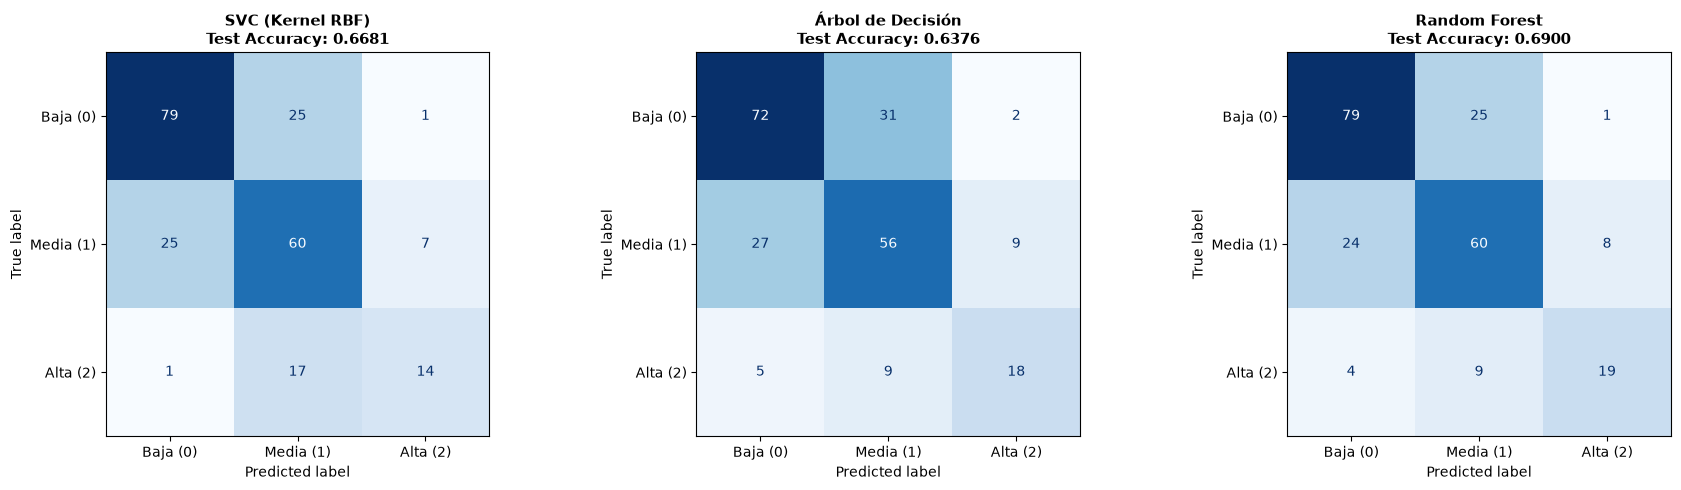

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

modelos = [
    ("SVC (Kernel RBF)", best_svc),
    ("Árbol de Decisión", best_dt),
    ("Random Forest", best_rf)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nombre, modelo) in zip(axes, modelos):
    y_pred = modelo.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    acc = accuracy_score(y_test, y_pred)
    ax.set_title(f"{nombre}\nTest Accuracy: {acc:.4f}", fontsize=11, fontweight='bold')
    
    print("=" * 60)
    print(f"REPORTE DE CLASIFICACIÓN: {nombre}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

plt.tight_layout()
plt.show()

### 4.2 Análisis de la métrica de evaluación (`accuracy` vs desbalanceo de clases)

* **¿Qué métrica usa `GridSearchCV` por defecto?**
  Por defecto, `GridSearchCV` utiliza el método `.score()` del estimador, que en clasificación corresponde a la **exactitud global (*accuracy*)**: proporción total de predicciones correctas sobre el total de muestras.
* **¿Es adecuada para este dataset?:**
  **No es la métrica ideal por sí sola**, debido a que nuestro dataset presenta un **desbalanceo moderado de clases**:
  * **Clase 0 (Baja):** ~45.7% de los datos.
  * **Clase 1 (Media):** ~40.4% de los datos.
  * **Clase 2 (Alta):** apenas **~13.9%** de los datos.
  
  Al optimizar exclusivamente *accuracy*, el modelo prioriza acertar en las clases mayoritarias (0 y 1) y puede tolerar una baja sensibilidad (*recall*) en la clase minoritaria (Clase 2: vinos de alta calidad). Para este problema, métricas como **`f1_macro`** o **`balanced_accuracy`** son más adecuadas porque otorgan el mismo peso a las tres categorías sin importar su frecuencia.

### 4.3 Experimento comparativo: efecto de `class_weight='balanced'`
Para comprobar el impacto del desbalanceo, reentrenamos los modelos activando `class_weight='balanced'` y comparamos las matrices de confusión y métricas por clase.

--- SVC (class_weight='balanced') ---
              precision    recall  f1-score   support

    Baja (0)     0.7551    0.7048    0.7291       105
   Media (1)     0.5000    0.4565    0.4773        92
    Alta (2)     0.3617    0.5312    0.4304        32

    accuracy                         0.5808       229
   macro avg     0.5389    0.5642    0.5456       229
weighted avg     0.5976    0.5808    0.5862       229

--- Random Forest (class_weight='balanced') ---
              precision    recall  f1-score   support

    Baja (0)     0.7800    0.7429    0.7610       105
   Media (1)     0.6392    0.6739    0.6561        92
    Alta (2)     0.6562    0.6562    0.6562        32

    accuracy                         0.7031       229
   macro avg     0.6918    0.6910    0.6911       229
weighted avg     0.7061    0.7031    0.7042       229



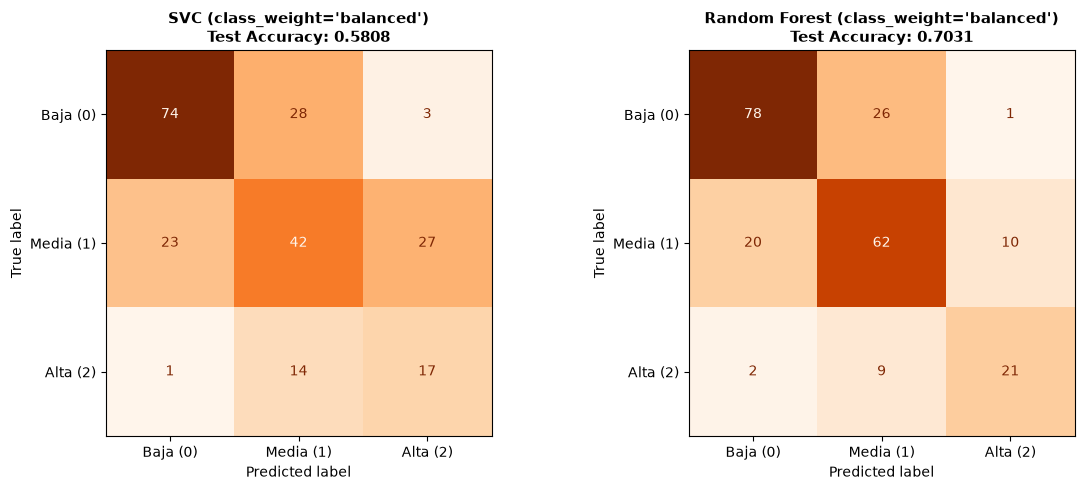

In [8]:
svc_bal = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', C=grid_svc.best_params_['svc__C'], gamma=grid_svc.best_params_['svc__gamma'], class_weight='balanced', random_state=42))
]).fit(X_train, y_train)

rf_bal = RandomForestClassifier(
    **grid_rf.best_params_, class_weight='balanced', random_state=42
).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, mod) in zip(axes, [("SVC (class_weight='balanced')", svc_bal), ("Random Forest (class_weight='balanced')", rf_bal)]):
    y_pred_b = mod.predict(X_test)
    cm_b = confusion_matrix(y_test, y_pred_b)
    ConfusionMatrixDisplay(cm_b, display_labels=class_names).plot(ax=ax, cmap='Oranges', colorbar=False)
    ax.set_title(f"{nombre}\nTest Accuracy: {accuracy_score(y_test, y_pred_b):.4f}", fontsize=11, fontweight='bold')
    print(f"--- {nombre} ---")
    print(classification_report(y_test, y_pred_b, target_names=class_names, digits=4))

plt.tight_layout()
plt.show()

**Observación del experimento con `class_weight='balanced'`:**
Al penalizar más los errores sobre la clase minoritaria, la **sensibilidad (*recall*) de la Clase 2 (Alta)** aumenta considerablemente (detectando más vinos de alta calidad que antes se confundían con calidad Media), a costa de una ligera disminución en la precisión de esa clase y en la exactitud global (*accuracy*).

---
### 4.4 Ventajas y desventajas: SVC vs. Random Forest en este dataset

| Criterio | SVC (Kernel RBF) | Random Forest |
| :--- | :--- | :--- |
| **Fronteras de decisión** | Genera fronteras suaves y no lineales en el espacio continuo de propiedades fisicoquímicas, capturando bien transiciones graduales entre calidades. | Construye ensambles de particiones ortogonales (escalonadas), reduciendo drásticamente la varianza frente a un único árbol de decisión. |
| **Preprocesamiento** | **Muy sensible a la escala:** exige estandarización (`StandardScaler`) dentro de un `Pipeline` para que variables como `total sulfur dioxide` (0–289) no dominen sobre `density` (~0.99). | **Invariante a transformaciones monótonas:** no requiere escalado de variables ni limpieza compleja de magnitudes. |
| **Sensibilidad a hiperparámetros** | Alta sensibilidad a la combinación $(C, \gamma)$; valores extremos degradan rápidamente la generalización. | Muy robusto; una vez alcanzado un número suficiente de árboles (`n_estimators`), es difícil que sobreajuste severamente. |
| **Interpretabilidad** | Baja (funciona como caja negra en un espacio implícito de dimensión infinita). | Media-alta: permite extraer directamente la importancia de cada variable (`feature_importances_`) para la enología. |
| **Desempeño y costo** | Excelente en datasets tabulares medianos como este ($N = 1,143$, $d = 6$), aunque su entrenamiento escala en $\mathcal{O}(N^2)$ a $\mathcal{O}(N^3)$ si creciera el número de muestras. | Paralelizable fácilmente (`n_jobs=-1`) y suele obtener la mejor exactitud y estabilidad en datos tabulares con variables correlacionadas. |